In [22]:
from utils import load_splits
import torch
import pandas as pd

In [4]:
#global random seed
SEED = 42
torch.manual_seed(SEED)

In [6]:
X_train, X_val, X_test, y_train, y_val, y_test = load_splits()

1
2
3


In [7]:
print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device

True
NVIDIA GeForce RTX 3050 6GB Laptop GPU


device(type='cuda')

In [56]:
import glob
import json
from pathlib import Path
logs = {}
for file in Path("logs").glob("*json"):
    with open(file, "r", encoding = "utf-8") as f:
        logs[f.name[5:-5]] = json.load(f)
        

In [57]:
logs

{'distilbert_lr_2e-05': [{'learning_rate': 2e-05,
   'epoch': 1.0,
   'val_loss': 0.19033536314964294,
   'val_accuracy': 0.9388192435444123,
   'val_precision': 0.9370884027621696,
   'val_recall': 0.9401892706811786,
   'val_f1': 0.9382928537480875},
  {'learning_rate': 2e-05,
   'epoch': 2.0,
   'val_loss': 0.2486323118209839,
   'val_accuracy': 0.9442837244187292,
   'val_precision': 0.9450130765467284,
   'val_recall': 0.9421352083027416,
   'val_f1': 0.9434110423862389},
  {'learning_rate': 2e-05,
   'epoch': 3.0,
   'val_loss': 0.32010018825531006,
   'val_accuracy': 0.9447123111539698,
   'val_precision': 0.9449041972707248,
   'val_recall': 0.9430522866231739,
   'val_f1': 0.9439059408805274},
  {'learning_rate': 2e-05,
   'epoch': 4.0,
   'val_loss': 0.3606273829936981,
   'val_accuracy': 0.9451408978892103,
   'val_precision': 0.9438723969021425,
   'val_recall': 0.945346237867881,
   'val_f1': 0.9445480698139979},
  {'learning_rate': 2e-05,
   'epoch': 5.0,
   'val_loss': 0

In [72]:
val_metrics = []
for k, log in logs.items():
    if isinstance(log, list):
        for epoch in log:
            epoch["model"] = f"{k[0]}_lr{epoch['learning_rate']:.0e}_e{epoch["epoch"]:.0f}"
            val_metrics.append(epoch)
            #val_metrics[f"{k}_epoch_{epoch["epoch"]:.0f}"] = epoch
    else:
        val_metrics.append(log)
        log["model"] = "tfidf"


In [73]:
val = pd.DataFrame(val_metrics)

val = val.sort_values("model").reset_index(drop=True)

val

,learning_rate,epoch,val_loss,val_accuracy,val_precision,val_recall,val_f1,model
0,0.00001,1.0,0.188255,0.936891,0.935136,0.938333,0.936358,b_lr1e-05_e1
1,0.00001,2.0,0.297194,0.941819,0.943423,0.938927,0.940811,b_lr1e-05_e2
2,0.00001,3.0,0.325295,0.944927,0.944162,0.944332,0.944246,b_lr1e-05_e3
3,0.00001,4.0,0.365882,0.944498,0.943997,0.943560,0.943774,b_lr1e-05_e4
4,0.00001,5.0,0.413880,0.943641,0.943211,0.942595,0.942894,b_lr1e-05_e5
5,0.00002,1.0,0.205221,0.940962,0.939199,0.942891,0.940505,b_lr2e-05_e1
6,0.00002,2.0,0.305928,0.941819,0.943769,0.938686,0.940777,b_lr2e-05_e2
7,0.00002,3.0,0.351837,0.945034,0.943979,0.944863,0.944401,b_lr2e-05_e3
8,0.00002,4.0,0.432079,0.945891,0.944771,0.945852,0.945280,b_lr2e-05_e4
9,0.00002,5.0,0.489235,0.944177,0.943430,0.943536,0.943483,b_lr2e-05_e5


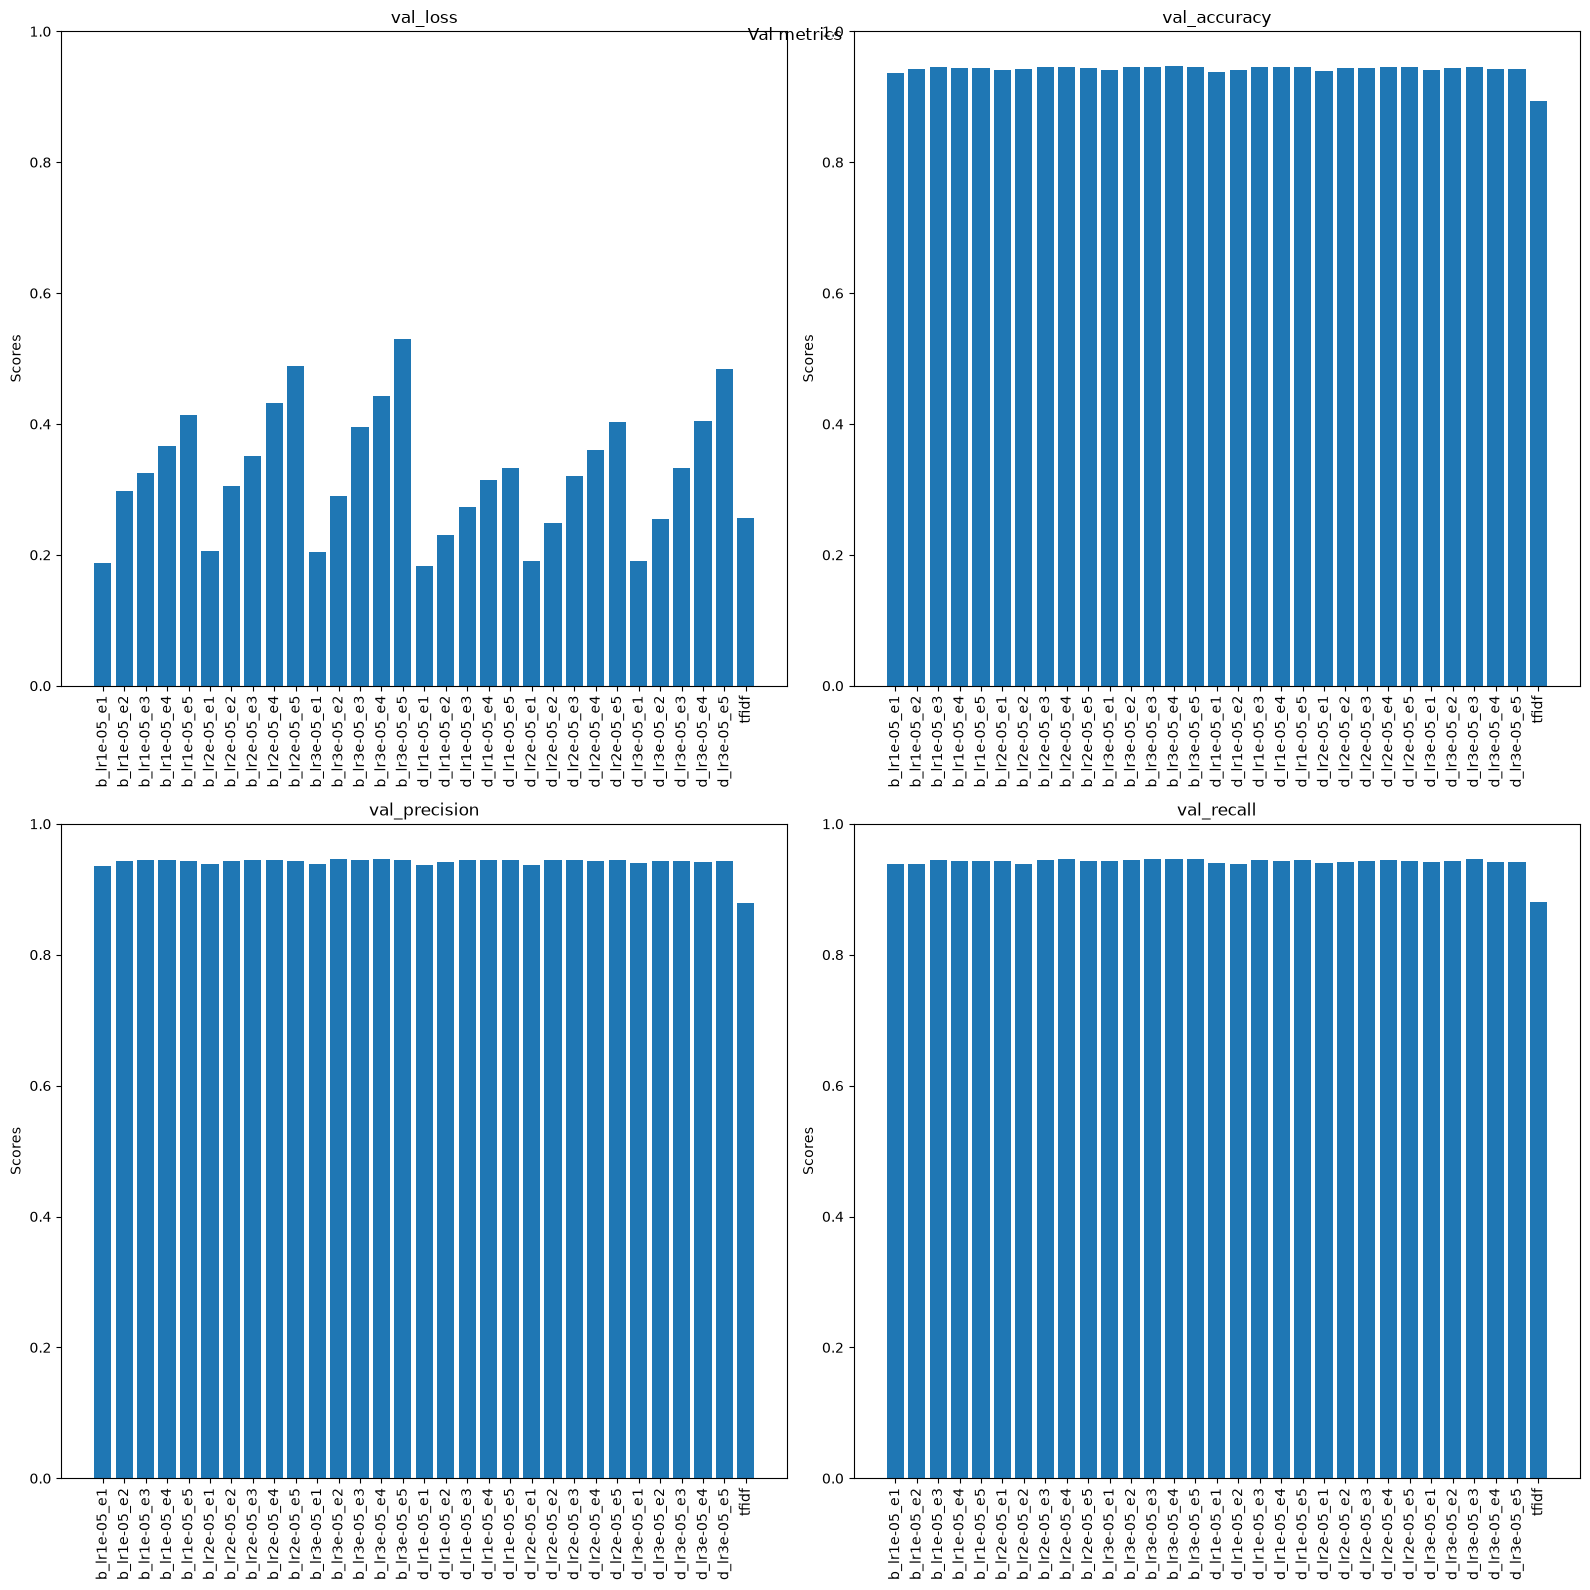

In [76]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2,2, figsize = (16,16))

metrics = ['val_loss', 'val_accuracy', 'val_precision', 'val_recall']

for index, metric in enumerate(metrics):
    i = index // 2
    j = index % 2

    axes[i, j].bar(val['model'], val[metric])
    axes[i,j].set_title(metric)
    axes[i,j].set_ylim(0,1)
    axes[i,j].set_ylabel('Scores')
    axes[i,j].tick_params(axis="x", labelrotation=90)
plt.tight_layout()
fig.suptitle("Val metrics")
plt.show()



In [80]:
val[val["val_loss"]==val["val_loss"].min()]

,learning_rate,epoch,val_loss,val_accuracy,val_precision,val_recall,val_f1,model
15,0.00001,1.0,0.182605,0.938176,0.936442,0.939538,0.937644,d_lr1e-05_e1
